# Tarea 23: Arboles de desicion

In [40]:
# load libraries for decision tree visualization
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
import matplotlib.pyplot as plt

In [41]:
# load dataset for drug 
drug_data_frame = pd.read_csv('drugs.csv')
drug_data_frame.sample(5)


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
82,32,F,LOW,HIGH,9.712,drugC
176,48,M,HIGH,NORMAL,10.446,drugA
49,28,F,LOW,HIGH,19.796,drugY
24,33,F,LOW,HIGH,33.486,drugY
134,42,F,HIGH,HIGH,21.036,drugY


In [42]:
# set the columns to used as feature matrix X and target variable Y
feature_columns = ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']
X = drug_data_frame[feature_columns].values
Y = drug_data_frame.Drug

In [43]:
# Preprocessing to generate numerical values from categorical values
from sklearn import preprocessing

sex_codfication = preprocessing.LabelEncoder()
sex_codfication.fit(['F', 'M'])
X[:, 1] = sex_codfication.transform(X[:, 1])

bp_status_codfication = preprocessing.LabelEncoder()
bp_status_codfication.fit(['HIGH', 'LOW', 'NORMAL'])
X[:, 2] = bp_status_codfication.transform(X[:, 2])

cholesterol_status_codfication = preprocessing.LabelEncoder()
cholesterol_status_codfication.fit(['HIGH', 'NORMAL'])
X[:, 3] = bp_status_codfication.transform(X[:, 3])

In [44]:
X[0:5]

array([[23, 0, 0, 0, 25.355],
       [47, 1, 1, 0, 13.093],
       [47, 1, 1, 0, 10.114],
       [28, 0, 2, 0, 7.798],
       [61, 0, 1, 0, 18.043]], dtype=object)

In [45]:
# Build the trainig and testing sets 
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)

## Gini

In [46]:
# Build the desicion tree classifier model
clf = DecisionTreeClassifier(criterion='gini')

# Apply the model to the training data 
clf = clf.fit(X_train, Y_train)

# Predict the response for the test dataset
y_hat = clf.predict(X_test)


In [47]:
# Confussion matrix
confusion_matrix = metrics.confusion_matrix(Y_test, y_hat)
confusion_matrix

array([[ 4,  0,  0,  0,  0],
       [ 0,  2,  0,  0,  0],
       [ 0,  0,  4,  0,  0],
       [ 0,  0,  0, 13,  0],
       [ 0,  0,  0,  0, 17]])

In [48]:
# Show the report of the model
print(metrics.classification_report(Y_test, y_hat))

              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       1.00      1.00      1.00         4
       drugX       1.00      1.00      1.00        13
       drugY       1.00      1.00      1.00        17

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



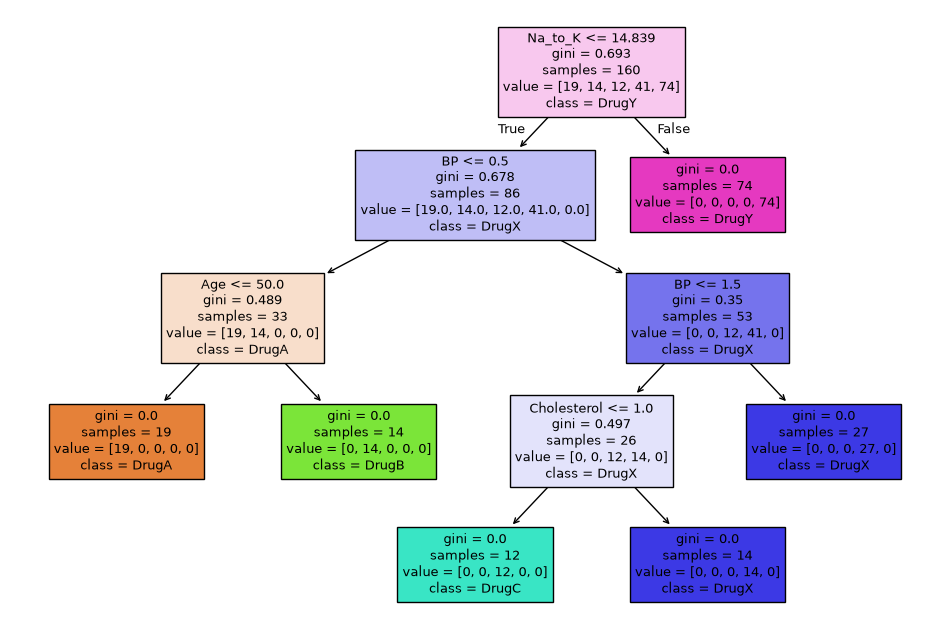

In [49]:
from sklearn import tree
plt.figure(figsize=(12,8))
tree.plot_tree(clf, filled=True, feature_names=feature_columns, class_names=['DrugA', 'DrugB', 'DrugC', 'DrugX', 'DrugY'])
plt.show()

## Entropia

In [50]:
# Build the desicion tree classifier model
clf = DecisionTreeClassifier(criterion='entropy')

# Apply the model to the training data 
clf = clf.fit(X_train, Y_train)

# Predict the response for the test dataset
y_hat = clf.predict(X_test)


In [51]:
# Confussion matrix
confusion_matrix = metrics.confusion_matrix(Y_test, y_hat)
confusion_matrix

array([[ 4,  0,  0,  0,  0],
       [ 0,  2,  0,  0,  0],
       [ 0,  0,  4,  0,  0],
       [ 0,  0,  0, 13,  0],
       [ 0,  0,  0,  0, 17]])

In [52]:
# Show the report of the model
print(metrics.classification_report(Y_test, y_hat))

              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         2
       drugC       1.00      1.00      1.00         4
       drugX       1.00      1.00      1.00        13
       drugY       1.00      1.00      1.00        17

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



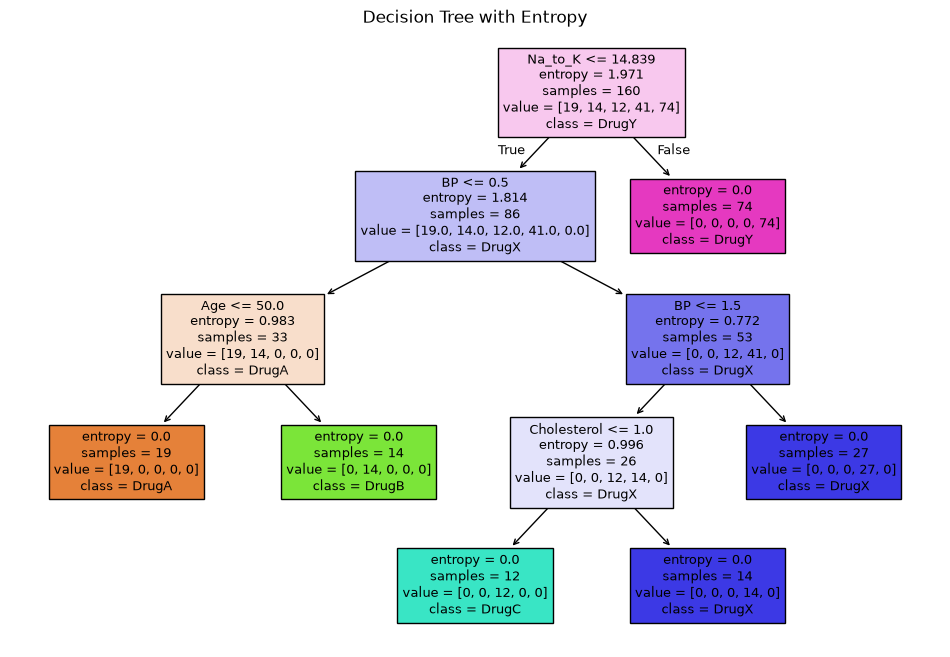

In [53]:
plt.figure(figsize=(12,8))
tree.plot_tree(clf, filled=True, feature_names=feature_columns, class_names=['DrugA', 'DrugB', 'DrugC', 'DrugX', 'DrugY'])
plt.title('Decision Tree with Entropy')
plt.show()